In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report 
from sklearn import metrics
import matplotlib.pyplot as plt 
import warnings 
warnings.filterwarnings("ignore")
import os
os.chdir("/Users/lleid/Downloads")
#"C:\Users\lleid\Downloads\diabetes.csv"

In [7]:
# Lee el csv y lo guarda en una variable llamada "df"
df = pd.read_csv("Drugs.csv")

df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [8]:
from sklearn import preprocessing   
le = preprocessing.LabelEncoder()

columnas_texto = ["Sex", "BP", "Cholesterol"]

for col in columnas_texto:
    # fit_transform = aprende las categorías y las cambia por 0, 1, 2...
    df[col] = le.fit_transform(df[col])
    # classes_ muestra el orden: la posición en la lista es el número asignado
    print(col, "->", list(le.classes_))

print(df.head())   # ahora Sex, BP y Cholesterol ya son números

Sex -> ['F', 'M']
BP -> ['HIGH', 'LOW', 'NORMAL']
Cholesterol -> ['HIGH', 'NORMAL']
   Age  Sex  BP  Cholesterol  Na_to_K   Drug
0   23    0   0            0   25.355  drugY
1   47    1   1            0   13.093  drugC
2   47    1   1            0   10.114  drugC
3   28    0   2            0    7.798  drugX
4   61    0   1            0   18.043  drugY


In [9]:
nacionales = ["drugA", "drugB", "drugC"]
df["label"] = df["Drug"].apply(lambda d: 0 if d in nacionales else 1)

# Selección de las características (las columnas que sirven para predecir)
feature_cols = ["Age", "Sex", "BP", "Cholesterol", "Na_to_K"]
X = df[feature_cols]
y = df.label   # lo que queremos predecir

In [5]:
df

,Age,Sex,BP,Cholesterol,Na_to_K,Drug,label
0,23,0,0,0,25.355,drugY,1
1,47,1,1,0,13.093,drugC,0
2,47,1,1,0,10.114,drugC,0
3,28,0,2,0,7.798,drugX,1
4,61,0,1,0,18.043,drugY,1
...,...,...,...,...,...,...,...
195,56,0,1,0,11.567,drugC,0
196,16,1,1,0,12.006,drugC,0
197,52,1,2,0,9.894,drugX,1
198,23,1,2,1,14.020,drugX,1


In [10]:
#Aqui partimos los datos para las bases de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 1)

In [11]:
#Regresion logistica con solucionador (SAG)
model = LogisticRegression(solver = "sag")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Intercepto (Beta0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("------------------------------------------------------------------------------------------------------------")

score = model.score(X_test, y_test)
print("Precision global:", score)
print("---------------------------------------------------------------------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0): [-0.31138093]
Pesos (Betas): [[-0.03741938 -0.15887911  1.02849715  0.20136487  0.16021501]]
------------------------------------------------------------------------------------------------------------
Precision global: 0.9
---------------------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.60      0.75        10
           1       0.88      1.00      0.94        30

    accuracy                           0.90        40
   macro avg       0.94      0.80      0.84        40
weighted avg       0.91      0.90      0.89        40



In [12]:
#Regresion logistica con solucionador (NEWTON-CG)
model = LogisticRegression(solver = "newton-cg")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Intercepto (Beta0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("------------------------------------------------------------------------------------------------------------")

score = model.score(X_test, y_test)
print("Precision global:", score)
print("---------------------------------------------------------------------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0): [-11.15250574]
Pesos (Betas): [[0.00660821 0.14830519 3.33610201 2.0724554  0.63787638]]
------------------------------------------------------------------------------------------------------------
Precision global: 0.975
---------------------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



In [13]:
#Regresion logistica con solucionador (liblinear)
model = LogisticRegression(solver = "liblinear")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Intercepto (Beta0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("------------------------------------------------------------------------------------------------------------")

score = model.score(X_test, y_test)
print("Precision global:", score)
print("---------------------------------------------------------------------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0): [-3.34051275]
Pesos (Betas): [[-0.02834219 -0.26053256  2.06969328  1.09570978  0.27510142]]
------------------------------------------------------------------------------------------------------------
Precision global: 0.975
---------------------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



In [14]:
#Regresion logistica con solucionador (saga)
model = LogisticRegression(solver = "saga")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Intercepto (Beta0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("------------------------------------------------------------------------------------------------------------")

score = model.score(X_test, y_test)
print("Precision global:", score)
print("---------------------------------------------------------------------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0): [-0.14482841]
Pesos (Betas): [[-0.03370567 -0.09321009  0.66323319  0.10400394  0.15454864]]
------------------------------------------------------------------------------------------------------------
Precision global: 0.875
---------------------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.86      0.60      0.71        10
           1       0.88      0.97      0.92        30

    accuracy                           0.88        40
   macro avg       0.87      0.78      0.81        40
weighted avg       0.87      0.88      0.87        40



In [15]:
#Regresion logistica con solucionador (lbfgs)
model = LogisticRegression(solver = "lbfgs")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Intercepto (Beta0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("------------------------------------------------------------------------------------------------------------")

score = model.score(X_test, y_test)
print("Precision global:", score)
print("---------------------------------------------------------------------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0): [-11.16791614]
Pesos (Betas): [[0.00667297 0.14894912 3.33863745 2.07461152 0.63862512]]
------------------------------------------------------------------------------------------------------------
Precision global: 0.975
---------------------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



In [17]:
#Prediccion de probabilidades para casos particulares 
y_pred_probs = clf.predict_proba(X_test)[:,1]
y_pred_probs[0:5]
#Probabilidades de que estas 5 drogas sean internacionales

array([0.9898257 , 0.99974436, 0.99355295, 0.67717001, 0.99999695])

In [18]:
y_test[0:5]
#valores reales

58     1
40     1
34     1
102    0
184    1
Name: label, dtype: int64

In [19]:
#Graficacion de la curva ROC y calculo del area bajo ella 
from sklearn.metrics import roc_curve 
from sklearn.metrics import roc_auc_score
# fpr = false positive rate 
# tpr = true positive rate 
# thresholds = limites para valores de p 
fpr, tpr, thresholds = roc_curve(y_test, y_pred_probs)
auc = roc_auc_score(y_test, y_pred_probs)

Text(0.5, 1.0, 'Curva ROC para regresion logistica(solver: LBFGS)')

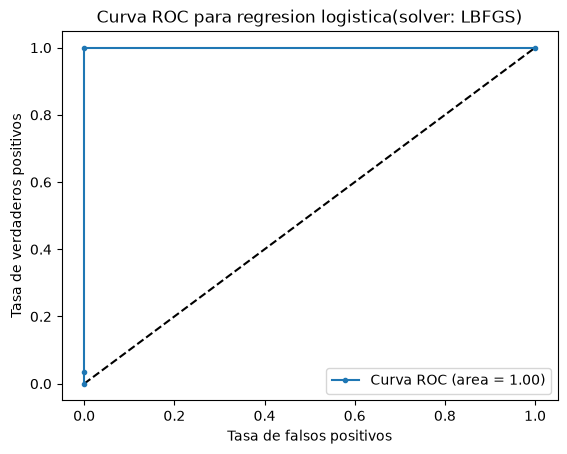

In [20]:
plt.plot([0,1],[0,1], 'k--')
plt.plot(fpr,tpr, marker =".", label = "Curva ROC (area = %0.2f)" % auc)
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc = "lower right")
plt.title("Curva ROC para regresion logistica(solver: LBFGS)")

In [21]:
import pandas as pd
import numpy as np

# Convierte a arreglos simples
y_real = np.asarray(y_test)    # original
y_modelo = np.asarray(y_pred)  # lo que dijo el modelo

# Nombres legibles en lugar de 0 y 1
nombres = {0: "Nacional", 1: "Extranjero"}
observado = pd.Series(y_real).map(nombres)
predicho = pd.Series(y_modelo).map(nombres)

# Tabla cruzada: filas = observado, columnas = predicho, con totales (margins)
tabla = pd.crosstab(observado, predicho, rownames=["Observado"],
                    colnames=["Predicho"], margins=True, margins_name="Total")

# % correcto de cada fila: aciertos de esa clase entre el total de esa clase
for clase in ["Nacional", "Extranjero"]:
    tabla.loc[clase, "% correcto"] = 100 * tabla.loc[clase, clase] / tabla.loc[clase, "Total"]

# % correcto global (exactitud)
tabla.loc["Total", "% correcto"] = 100 * (y_real == y_modelo).mean()

print(tabla.round(1))

Predicho    Extranjero  Nacional  Total  % correcto
Observado                                          
Extranjero          30         0     30       100.0
Nacional             1         9     10        90.0
Total               31         9     40        97.5


In [ ]:
#¿Qué tan eficaz es el algoritmo predictivo escogido?
#El algoritmo escogido fue la regresión logística con el solucionador LBFGS,
#y resultó muy eficaz para clasificar si un fármaco es de origen nacional o extranjero.
#El modelo tuvo una exactitud global de 97.5%: de los 40 pacientes de prueba, acertó en 39 y solo falló en 1.
#La curva se pega a la esquina superior izquierda y el área bajo la curva (AUC) es 1.00. Esto indica que el modelo separa perfectamente los dos grupos
#a todos los pacientes con fármaco extranjero les asigna una probabilidad más alta que a todos los de fármaco nacional.